# DiT：用 Transformer 生成图像

语言模型处理字符，DiT 处理图片小块，并额外接收一个时间。本例用 **Flow Matching** 训练 DiT：从噪声走向真实图片，模型负责预测每一步应该往哪里移动。

先完成四次参数更新，再看一次采样过程；此时还不能生成清晰数字。

In [1]:
from qutai import Stream, generation, nn, visualization
from examples.data.data import load_mnist

device = "apple"

## 1. 看一张图片

仍然使用 MNIST。数据读取放在 `examples/data/data.py`，Notebook 只负责展示模型与训练。

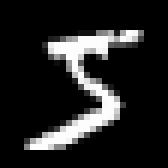

In [2]:
images, _ = load_mnist("train")
visualization.Image.from_tensor(images[0], value_range=(0, 1))

## 2. 搭模型和数据流

`DiT` 把 28×28 图片切成 7×7 的小块。`generation.Model` 把网络和生成方法放在一起。

`Stream` 为每张图片随机准备噪声和时间，输出三项：`inputs` 是当前图片，`times` 是当前时间，`targets` 是从噪声走向原图的速度。

In [3]:
method = generation.FlowMatching(steps=8)
model = generation.Model(
    nn.DiT(1, 28, patch_size=7, features=8, heads=2, hidden_features=16),
    method=method,
).to(device)
optimizer = nn.SGD(model, learning_rate=0.001)
loss_function = nn.MSE()
# 生成数据流额外返回每张图对应的时间 times。
data = Stream(images, method=method, batch_size=2, limit=4, progress=False, device=device)

## 3. 训练

循环和其他教程相同，只是 DiT 还需要接收 `times`。预测速度与目标速度越接近，MSE 越小。

In [5]:
epochs = 20
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, times, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs, times), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.4f}")

epoch 1/20  loss 1.9860
epoch 2/20  loss 1.9322
epoch 3/20  loss 1.8496
epoch 4/20  loss 1.8994
epoch 5/20  loss 1.9252
epoch 6/20  loss 1.9425
epoch 7/20  loss 2.0048
epoch 8/20  loss 1.9493
epoch 9/20  loss 1.9394
epoch 10/20  loss 1.8957
epoch 11/20  loss 1.8673
epoch 12/20  loss 1.9156
epoch 13/20  loss 1.8558
epoch 14/20  loss 1.8881
epoch 15/20  loss 1.8947
epoch 16/20  loss 1.8738
epoch 17/20  loss 2.0119
epoch 18/20  loss 1.9335
epoch 19/20  loss 1.8197
epoch 20/20  loss 2.0321


## 4. 从噪声开始采样

`trajectory()` 返回初始噪声和后面每一步的图片。这里每隔两步显示一张；训练更多轮后再观察最终图片是否逐渐接近数字。


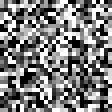
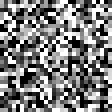
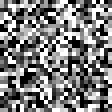
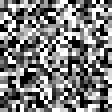
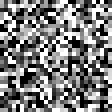

In [6]:
frames = model.trajectory()
visualization.ImageCombine([visualization.Image.from_tensor(frame[0], scale=4) for frame in frames[::2]], columns=5, labels=["噪声", "第 2 步", "第 4 步", "第 6 步", "第 8 步"])